# Book Market Analytics

This project analyses data scraped from Books to Scrape.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
df = pd.read_csv("books_dataset.csv")

df.head()

,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,NaN,In Stock
1,Tipping the Velvet,53.74,NaN,In Stock
2,Soumission,50.10,NaN,In Stock
3,Sharp Objects,47.82,NaN,In Stock
4,Sapiens: A Brief History of Humankind,54.23,NaN,In Stock


In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         220 non-null    str    
 1   Price         220 non-null    float64
 2   Rating        0 non-null      float64
 3   Availability  220 non-null    str    
dtypes: float64(2), str(2)
memory usage: 7.0 KB


In [43]:
df.describe()

,Price,Rating
count,220.000000,0.0
mean,34.360909,NaN
std,14.142035,NaN
min,10.160000,NaN
25%,21.280000,NaN
50%,35.340000,NaN
75%,45.715000,NaN
max,59.640000,NaN


In [44]:
df.isnull().sum()

Title             0
Price             0
Rating          220
Availability      0
dtype: int64

In [45]:
df.duplicated().sum()

np.int64(0)

In [46]:
df.drop_duplicates(inplace=True)

C:\Users\thash\AppData\Local\Temp\ipykernel_11048\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [47]:
df["Price"] = df["Price"].astype(str)

df["Price"] = df["Price"].str.replace("Â£", "", regex=False)

df["Price"] = pd.to_numeric(
    df["Price"],
    errors="coerce"
)
df["Price"].head()

0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: Price, dtype: float64

In [48]:
rating_map = {
    "One":1,
    "Two":2,
    "Three":3,
    "Four":4,
    "Five":5
}

df["Rating"] = df["Rating"].map(rating_map)

In [49]:
df.to_csv(
    "books_dataset.csv",
    index=False
)

Data Visualisation

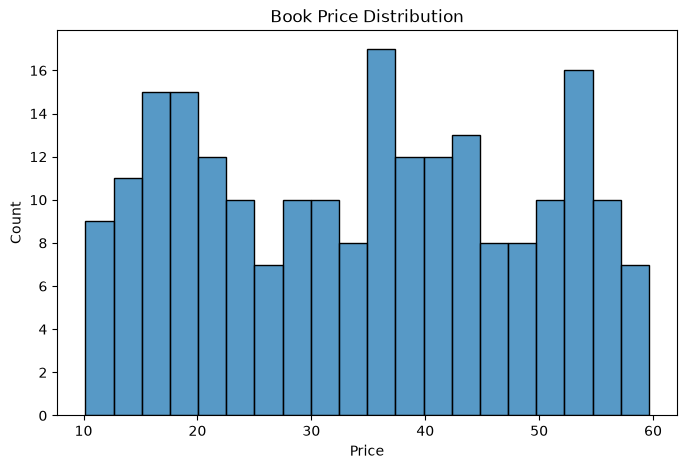

In [50]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Price"],
    bins=20
)

plt.title("Book Price Distribution")

plt.show()

#Most books fall into the mid-price range.

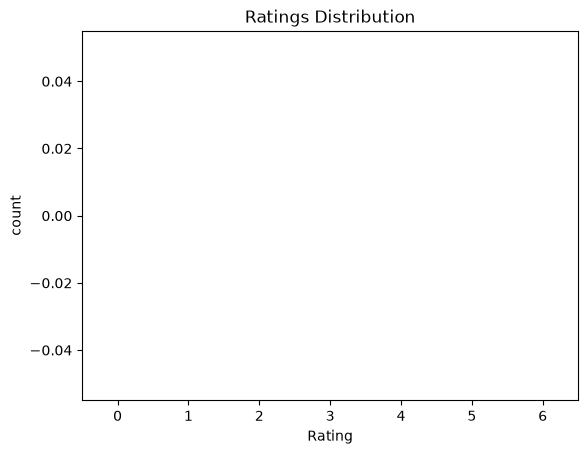

In [51]:
sns.countplot(
    x="Rating",
    data=df
)

plt.title("Ratings Distribution")

plt.show()

float64
float64
0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: Price, dtype: float64
0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: Rating, dtype: float64


ValueError: List of boxplot statistics and `positions` values must have same the length

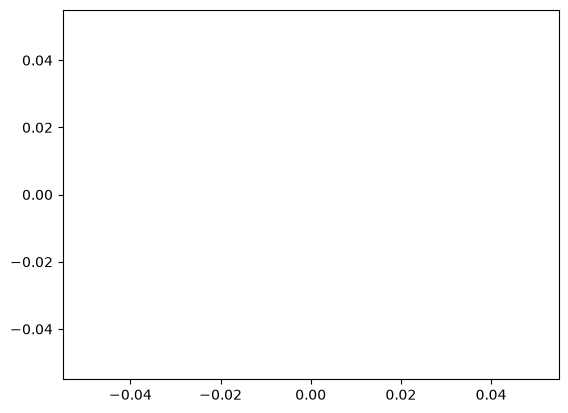

In [53]:
sns.boxplot(
    x="Rating",
    y="Price",
    data=df
)

plt.title("Price by Rating")

plt.show()

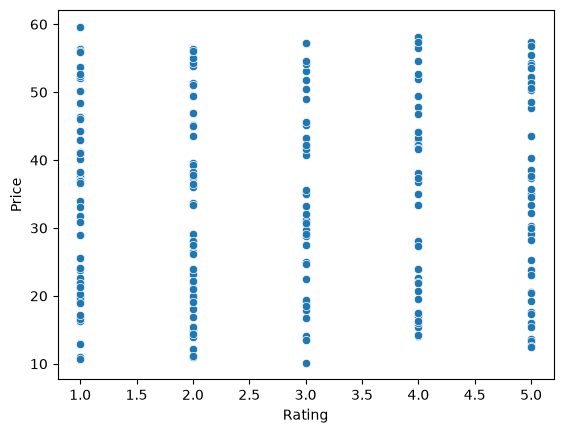

In [ ]:
sns.scatterplot(
    x="Rating",
    y="Price",
    data=df
)

plt.show()

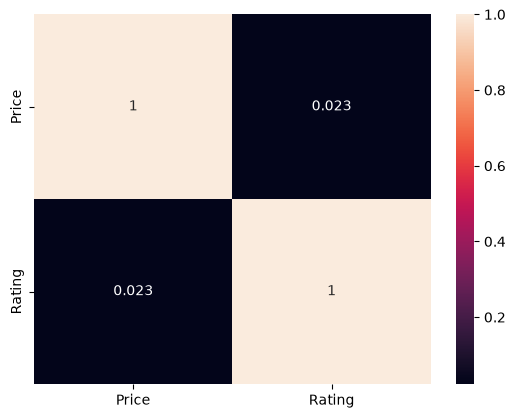

In [ ]:
sns.heatmap(
    df[["Price","Rating"]].corr(),
    annot=True
)

plt.show()

C:\Users\thash\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128 (\x80) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\thash\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 156 (\x9c) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\thash\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 157 (\x9d) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


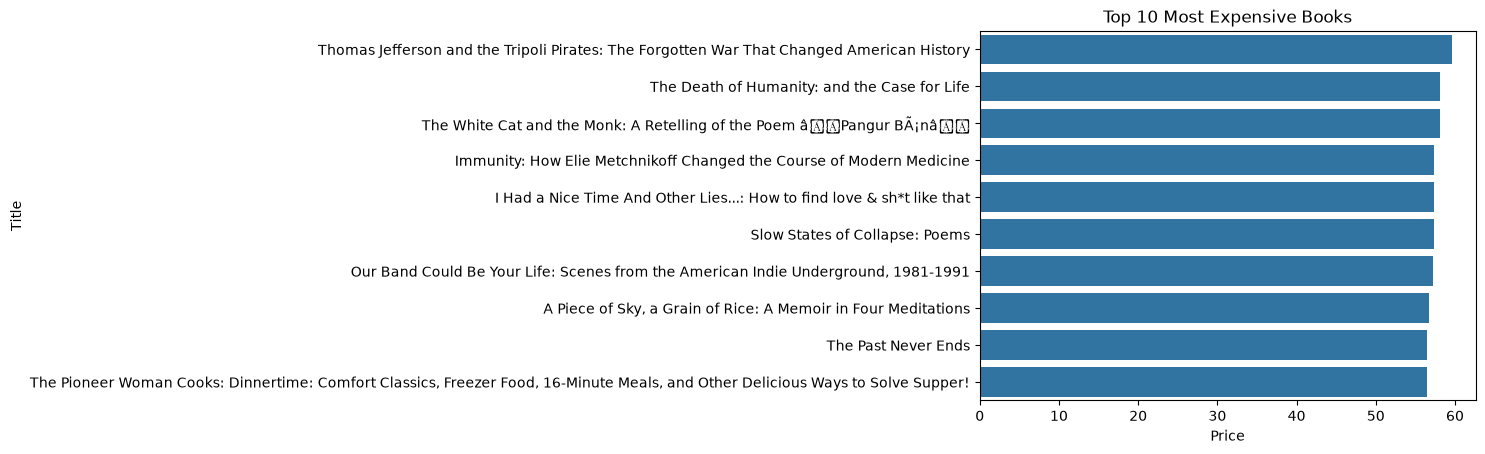

In [ ]:
top_books = (
    df.sort_values(
        by="Price",
        ascending=False
    )
    .head(10)
)

sns.barplot(
    x="Price",
    y="Title",
    data=top_books
)

plt.title(
    "Top 10 Most Expensive Books"
)

plt.show()

Predictive Modelling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
print("Hello world")